# Tahap 4: Clustering, Analisis Sensitivitas, dan Peta Interaktif
**Project Akhir Data Wrangling: Indeks Risiko Bencana Terpadu Kab/Kota di Jawa**

Input: `tahap3_features.csv` (dicari otomatis). Untuk peta, file batas wilayah `kabkota_jabar_jateng_jatim.geojson` juga dicari otomatis (kalau tidak ada, bagian peta dilewati).
Output: `data/interim/tahap4_hasil.csv` dan `peta_risiko_jawa.html`.

Alur: clustering K-Means pada skor komponen (Z-score), penentuan jumlah klaster, pembanding Hierarchical (Ward), uji stabilitas, profil klaster, analisis sensitivitas indeks, peta, dan daftar wilayah prioritas.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

SEED = 42
N_INIT = 50
K_PILIHAN = None
K_MIN, K_MAX = 3, 6

hit = sorted(Path(".").rglob("features*.csv"))
assert hit, "features.csv tidak ditemukan: jalankan tahap 3 sampai akhir atau upload filenya"
OUT = Path("data/interim"); OUT.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(hit[0])
df["CC_2"] = df["CC_2"].astype(str)
print("file:", hit[0], "| bentuk:", df.shape)

file: features.csv | bentuk: (100, 94)


## 1. Data untuk clustering
Clustering dilakukan pada **5 skor komponen** (gempa, karhutla, lingkungan, paparan, kapasitas), bukan 13 fitur mentah. Alasannya: dengan hanya 100 wilayah, dimensi yang rendah lebih stabil, dan hasilnya langsung bisa dibaca sebagai profil risiko. Skor distandarkan (**Z-score**) supaya semua komponen punya pengaruh setara dalam perhitungan jarak.

In [2]:
KOMP = ["skor_gempa", "skor_karhutla", "skor_lingkungan", "skor_paparan", "skor_kapasitas"]
X = StandardScaler().fit_transform(df[KOMP])
print(pd.DataFrame(X, columns=KOMP).describe().loc[["mean", "std"]].round(3))

      skor_gempa  skor_karhutla  skor_lingkungan  skor_paparan  skor_kapasitas
mean       0.000         -0.000           -0.000         0.000          -0.000
std        1.005          1.005            1.005         1.005           1.005


## 2. Menentukan jumlah klaster
Empat metrik: **inertia** (Elbow, makin kecil makin rapat), **Silhouette** (makin besar makin baik, maks 1), **Davies-Bouldin** (makin kecil makin baik), **Calinski-Harabasz** (makin besar makin baik).
Selisih Silhouette antar k biasanya sangat kecil, jadi **memilih k bukan keputusan yang tegas**: coba beberapa nilai lewat `K_PILIHAN` dan laporkan hasilnya.
Aturan baca Silhouette: di bawah 0,25 = hampir tidak ada struktur klaster; 0,26 sampai 0,50 = struktur lemah sampai wajar; di atas 0,50 = struktur jelas.

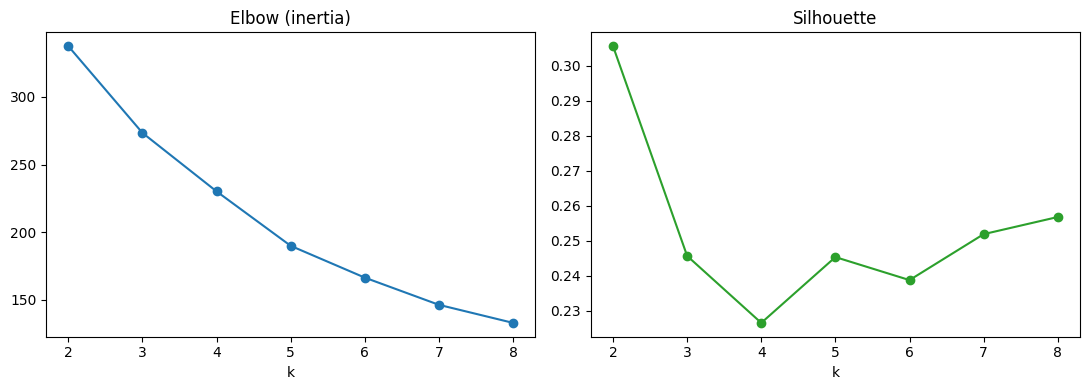

k terbaik menurut Silhouette pada rentang 3-6: 3 | k yang dipakai: 3


,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,337.550,0.306,1.267,47.164
3,273.439,0.246,1.366,40.185
4,230.190,0.227,1.332,37.508
5,189.943,0.245,1.198,38.769
6,166.433,0.239,1.172,37.679
7,146.327,0.252,1.132,37.464
8,132.983,0.257,1.089,36.273


In [3]:
baris = []
for k in range(2, 9):
    km = KMeans(k, n_init=N_INIT, random_state=SEED).fit(X)
    baris.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
                  "davies_bouldin": davies_bouldin_score(X, km.labels_),
                  "calinski_harabasz": calinski_harabasz_score(X, km.labels_)})
metrik = pd.DataFrame(baris).set_index("k")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(metrik.index, metrik["inertia"], marker="o"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(metrik.index, metrik["silhouette"], marker="o", color="tab:green"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

k_otomatis = int(metrik.loc[K_MIN:K_MAX, "silhouette"].idxmax())
K = K_PILIHAN or k_otomatis
print(f"k terbaik menurut Silhouette pada rentang {K_MIN}-{K_MAX}: {k_otomatis} | k yang dipakai: {K}")
metrik.round(3)

## 3. K-Means dan pembanding Hierarchical (Ward)
Dua algoritma dengan prinsip berbeda dibandingkan. **ARI** (Adjusted Rand Index) mengukur kesepakatan dua pengelompokan: 1 = identik, 0 = sama dengan acak.

         silhouette  davies_bouldin ukuran_klaster
K-Means       0.246           1.366   [54, 23, 23]
Ward          0.201           1.351   [38, 42, 20]
ARI K-Means vs Ward: 0.227


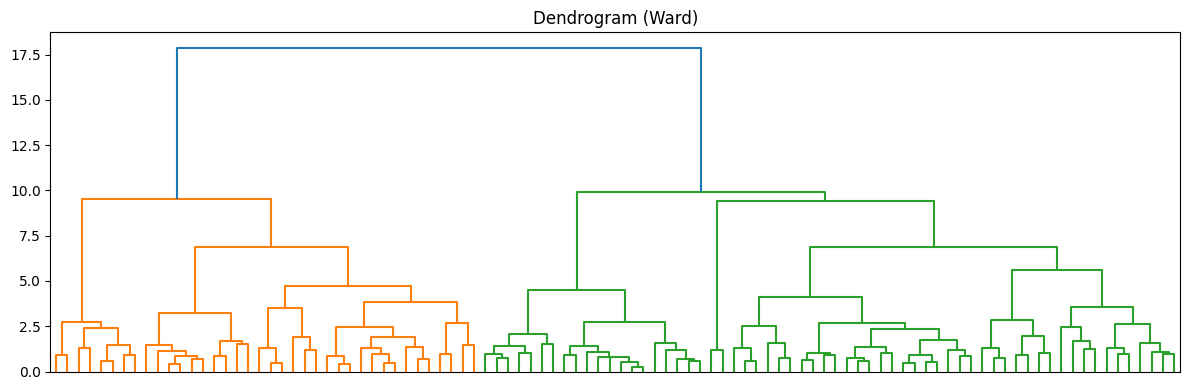

In [4]:
km = KMeans(K, n_init=N_INIT, random_state=SEED).fit(X)
ward = AgglomerativeClustering(K, linkage="ward").fit(X)

pembanding = pd.DataFrame({
    "silhouette": [silhouette_score(X, km.labels_), silhouette_score(X, ward.labels_)],
    "davies_bouldin": [davies_bouldin_score(X, km.labels_), davies_bouldin_score(X, ward.labels_)],
    "ukuran_klaster": [np.bincount(km.labels_).tolist(), np.bincount(ward.labels_).tolist()],
}, index=["K-Means", "Ward"]).round(3)
print(pembanding)
print("ARI K-Means vs Ward:", round(adjusted_rand_score(km.labels_, ward.labels_), 3))

plt.figure(figsize=(12, 4))
dendrogram(linkage(X, method="ward"), no_labels=True, color_threshold=None)
plt.title("Dendrogram (Ward)"); plt.tight_layout(); plt.show()

## 4. Uji stabilitas
Pertanyaan: kalau datanya sedikit berubah, apakah klasternya ikut berubah? Dua uji: (a) **bootstrap**: latih ulang pada sampel acak 100 wilayah (dengan pengembalian), lalu prediksi seluruh wilayah dan bandingkan dengan klaster utama; (b) **seed**: hasil dari inisialisasi acak berbeda.

In [5]:
rng = np.random.default_rng(SEED)
ari_boot = []
for b in range(100):
    idx = rng.choice(len(X), len(X), replace=True)
    kb = KMeans(K, n_init=10, random_state=b).fit(X[idx])
    ari_boot.append(adjusted_rand_score(km.labels_, kb.predict(X)))
ari_seed = [adjusted_rand_score(km.labels_, KMeans(K, n_init=1, random_state=s).fit(X).labels_) for s in range(30)]

print(f"Bootstrap (100x): ARI rata-rata {np.mean(ari_boot):.3f} | persentil ke-5 {np.percentile(ari_boot, 5):.3f}")
print(f"Seed berbeda (30x): ARI rata-rata {np.mean(ari_seed):.3f} | minimum {np.min(ari_seed):.3f}")

Bootstrap (100x): ARI rata-rata 0.500 | persentil ke-5 0.276
Seed berbeda (30x): ARI rata-rata 0.502 | minimum 0.248


## 5. Profil klaster
Klaster diberi nomor **berdasarkan rata-rata indeks risiko**: klaster 1 = risiko tertinggi. Deskripsi otomatis hanya menyebut komponen yang menyimpang jelas dari rata-rata (|Z| >= 0,5).

In [6]:
df["klaster_mentah"] = km.labels_
urut = df.groupby("klaster_mentah")["indeks_risiko"].mean().sort_values(ascending=False).index
peta_no = {lama: i + 1 for i, lama in enumerate(urut)}
df["klaster"] = df["klaster_mentah"].map(peta_no)

z = pd.DataFrame(X, columns=KOMP, index=df.index)
z["klaster"] = df["klaster"]
profil_z = z.groupby("klaster").mean()

def deskripsi(r):
    nama = {"skor_gempa": "gempa", "skor_karhutla": "karhutla", "skor_lingkungan": "tekanan lingkungan",
            "skor_paparan": "paparan", "skor_kapasitas": "kapasitas"}
    bagian = [f"{nama[c]} {'tinggi' if r[c] > 0 else 'rendah'}" for c in KOMP if abs(r[c]) >= 0.5]
    return ", ".join(bagian) if bagian else "mendekati rata-rata"

profil = df.groupby("klaster").agg(jumlah=("CC_2", "size"), indeks_risiko=("indeks_risiko", "mean"), irbi_skor=("irbi_skor", "mean"),
                                    **{c: (c, "mean") for c in KOMP}).round(2)
profil["ciri_khas"] = profil_z.apply(deskripsi, axis=1)
profil

,jumlah,indeks_risiko,irbi_skor,skor_gempa,skor_karhutla,skor_lingkungan,skor_paparan,skor_kapasitas,ciri_khas
klaster,,,,,,,,,
1,54,35.73,115.12,0.59,0.46,0.13,0.59,0.35,paparan tinggi
2,23,29.11,108.52,0.34,0.59,0.33,0.52,0.31,"gempa rendah, karhutla tinggi, tekanan lingkun..."
3,23,8.52,94.64,0.55,0.23,0.05,0.35,0.59,"karhutla rendah, tekanan lingkungan rendah, pa..."


In [7]:
for k in sorted(df["klaster"].unique()):
    sub = df[df["klaster"] == k].sort_values("indeks_risiko", ascending=False)
    print(f"Klaster {k} ({len(sub)} wilayah): " + ", ".join(sub["NAME_2"]))
    print()

Klaster 1 (54 wilayah): Cianjur, Bandung, Tasikmalaya, Sukabumi, Garut, Bandung Barat, Malang, Bogor, Cilacap, Brebes, Blitar, Tegal, Sumedang, Majalengka, Kediri, Ciamis, Lumajang, Pasuruan, Subang, Purwakarta, Cirebon, Sumenep, Ponorogo, Sukoharjo, Bondowoso, Magelang, Pangandaran, Kuningan, Probolinggo, Wonogiri, Karanganyar, Banyumas, Kebumen, Madiun, Situbondo, Jombang, Depok, Wonosobo, Magetan, Purbalingga, Mojokerto, Boyolali, Bekasi, Sragen, Pacitan, Pamekasan, Trenggalek, Pekalongan, Gresik, Banjarnegara, Klaten, Tulungagung, Temanggung, Purworejo

Klaster 2 (23 wilayah): Nganjuk, Jember, Grobogan, Pemalang, Banyuwangi, Ngawi, Bojonegoro, Tuban, Karawang, Blora, Indramayu, Sampang, Batang, Semarang, Demak, Jepara, Pati, Rembang, Sidoarjo, Kendal, Lamongan, Bangkalan, Kudus

Klaster 3 (23 wilayah): Kota Bekasi, Kota Tasikmalaya, Kota Bandung, Kota Bogor, Kota Sukabumi, Kota Malang, Cimahi, Banjar, Kota Semarang, Batu, Kota Pasuruan, Surabaya, Kota Probolinggo, Kota Tegal, Kota 

### Cek penting: apakah klaster hanya memisahkan Kota vs Kabupaten?
Kota biasanya berpenduduk lebih sedikit dan punya faskes per kapita lebih tinggi, jadi mudah terkumpul dalam satu klaster. Tabel di bawah menunjukkan sebaran jenis wilayah di tiap klaster.

In [8]:
pd.crosstab(df["klaster"], df["TYPE_2"], margins=True)

TYPE_2,Kabupaten,Kota,All
klaster,,,
1,53,1,54
2,23,0,23
3,0,23,23
All,76,24,100


## 6. Analisis sensitivitas indeks
Bobot dan lantai kapasitas di tahap 3 adalah **asumsi**. Di sini asumsi itu digoyang: seberapa besar urutan wilayah berubah? Ukurannya: **korelasi peringkat Spearman** terhadap indeks utama, jumlah wilayah yang tetap masuk **10 teratas**, dan korelasi dengan IRBI.

In [9]:
KOMPONEN = {
    "gempa": ["log_energi_100", "log_n_gempa_100", "n_gempa_50km", "dangkal_100"],
    "karhutla": ["log_karhutla_total", "karhutla_tren"],
    "lingkungan": ["gfw_loss_rasio"],
    "paparan": ["log_pop", "prop_rentan"],
    "kapasitas": ["faskes_per_100k", "rs_per_100k", "puskesmas_per_100k"],
}
mmk = lambda fs: df[[f"{f}_mm" for f in fs]].mean(axis=1)

def indeks_dari(bobot=(0.5, 0.3, 0.2), lantai=0.1, rumus="rasio", gempa_kolom=None):
    s = {k: mmk(fs) for k, fs in KOMPONEN.items()}
    if gempa_kolom:                                           # versi alternatif: skor gempa dari kolom lain
        s["gempa"] = mmk(gempa_kolom)
    bahaya = bobot[0] * s["gempa"] + bobot[1] * s["karhutla"] + bobot[2] * s["lingkungan"]
    if rumus == "rasio":
        r = bahaya * s["paparan"] / (lantai + (1 - lantai) * s["kapasitas"])
    else:                                                      # rumus alternatif: bahaya x paparan x (1 - kapasitas)
        r = bahaya * s["paparan"] * (1 - s["kapasitas"])
    return (r - r.min()) / (r.max() - r.min()) * 100

dasar = indeks_dari()
assert np.allclose(dasar, df["indeks_risiko"]), "indeks dasar tidak sama dengan tahap 3: cek file tahap3_features.csv"
print("indeks dasar identik dengan tahap 3: OK")

indeks dasar identik dengan tahap 3: OK


In [10]:
skenario = {
    "dasar (0.5/0.3/0.2, lantai 0.1)": dict(),
    "gempa dominan (0.7/0.2/0.1)": dict(bobot=(0.7, 0.2, 0.1)),
    "seimbang (1/3 masing-masing)": dict(bobot=(1/3, 1/3, 1/3)),
    "karhutla dominan (0.3/0.5/0.2)": dict(bobot=(0.3, 0.5, 0.2)),
    "tanpa tekanan lingkungan (0.6/0.4/0)": dict(bobot=(0.6, 0.4, 0.0)),
    "hanya gempa (1/0/0)": dict(bobot=(1.0, 0.0, 0.0)),
    "lantai kapasitas 0.05": dict(lantai=0.05),
    "lantai kapasitas 0.2": dict(lantai=0.2),
    "rumus alternatif x (1 - kapasitas)": dict(rumus="kurang"),
    "gempa: hitungan radius 50 km saja": dict(gempa_kolom=["n_gempa_50km", "dangkal_100"]),
    "gempa: hitungan radius 100 km saja": dict(gempa_kolom=["n_gempa_100km", "dangkal_100"]),
    "gempa: hitungan radius 150 km saja": dict(gempa_kolom=["n_gempa_150km", "dangkal_100"]),
}
top_dasar = set(dasar.nlargest(10).index)
hasil_sens = []
for nama, p in skenario.items():
    v = indeks_dari(**p)
    hasil_sens.append({"skenario": nama,
                       "rho_vs_dasar": spearmanr(v, dasar)[0],
                       "top10_sama": len(top_dasar & set(v.nlargest(10).index)),
                       "rho_vs_IRBI": spearmanr(v, df["irbi_skor"])[0]})
sens = pd.DataFrame(hasil_sens).set_index("skenario").round(3)
sens

,rho_vs_dasar,top10_sama,rho_vs_IRBI
skenario,,,
"dasar (0.5/0.3/0.2, lantai 0.1)",1.000,10,0.365
gempa dominan (0.7/0.2/0.1),0.973,10,0.352
seimbang (1/3 masing-masing),0.983,9,0.374
karhutla dominan (0.3/0.5/0.2),0.978,9,0.360
tanpa tekanan lingkungan (0.6/0.4/0),0.987,10,0.352
hanya gempa (1/0/0),0.873,9,0.324
lantai kapasitas 0.05,0.996,10,0.357
lantai kapasitas 0.2,0.993,10,0.379
rumus alternatif x (1 - kapasitas),0.981,9,0.375


Catatan: skenario radius di atas hanya menguji **hitungan gempa** (energi dan magnitudo dihitung pada radius 100 km di tahap 1). Untuk menguji radius pada energi juga, ubah `RADIUS_UTAMA` di notebook tahap 1 lalu jalankan ulang.

In [11]:
sisa = ~df["diimputasi"].astype(bool)
km_sisa = KMeans(K, n_init=N_INIT, random_state=SEED).fit(X[sisa.values])
print("wilayah dikeluarkan:", df.loc[~sisa, "NAME_2"].tolist())
print("ARI klaster (tanpa vs dengan wilayah itu):", round(adjusted_rand_score(km.labels_[sisa.values], km_sisa.labels_), 3))

wilayah dikeluarkan: ['Pangandaran']
ARI klaster (tanpa vs dengan wilayah itu): 1.0


## 8. Peta interaktif
Dua lapisan yang bisa diganti lewat kontrol di pojok: **klaster** dan **indeks risiko (0-100)**. Arahkan kursor ke wilayah untuk melihat rinciannya.

In [12]:
import folium, branca.colormap as cm
import geopandas as gpd

gj = sorted(Path(".").rglob("kabkota_jabar_jateng_jatim*.geojson"))
if not gj:
    print("File batas wilayah tidak ditemukan: bagian peta dilewati. Upload kabkota_jabar_jateng_jatim.geojson lalu jalankan ulang sel ini.")
    m = None
else:
    gdf = gpd.read_file(gj[0])
    gdf["CC_2"] = gdf["CC_2"].astype(str)
    info = df[["CC_2", "NAME_2", "TYPE_2", "klaster", "indeks_risiko", "skor_bahaya", "skor_paparan", "skor_kapasitas", "irbi_skor"]].round(2)
    gdf = gdf[["CC_2", "geometry"]].merge(info, on="CC_2", how="inner")
    gdf["geometry"] = gdf.geometry.simplify(0.003)           # sederhanakan bentuk supaya file ringan
    assert len(gdf) == 100

    PALET = ["#b30000", "#e34a33", "#fc8d59", "#fdcc8a", "#9ecae1", "#6baed6", "#2171b5", "#08306b"]
    warna_klaster = {k: PALET[i] for i, k in enumerate(sorted(gdf["klaster"].unique()))}
    skala = cm.LinearColormap(["#ffffcc", "#fd8d3c", "#800026"], vmin=0, vmax=100, caption="Indeks risiko (0-100)")

    m = folium.Map(location=[-7.3, 109.6], zoom_start=7, tiles="OpenStreetMap")
    kolom = ["NAME_2", "TYPE_2", "klaster", "indeks_risiko", "skor_bahaya", "skor_paparan", "skor_kapasitas", "irbi_skor"]
    label = ["Wilayah", "Jenis", "Klaster", "Indeks risiko", "Bahaya", "Paparan", "Kapasitas", "IRBI BNPB"]

    folium.GeoJson(gdf, name="Klaster",
                   style_function=lambda f: {"fillColor": warna_klaster[f["properties"]["klaster"]], "color": "#555", "weight": 0.5, "fillOpacity": 0.8},
                   tooltip=folium.GeoJsonTooltip(fields=kolom, aliases=label)).add_to(m)
    folium.GeoJson(gdf, name="Indeks risiko", show=False,
                   style_function=lambda f: {"fillColor": skala(f["properties"]["indeks_risiko"]), "color": "#555", "weight": 0.5, "fillOpacity": 0.8},
                   tooltip=folium.GeoJsonTooltip(fields=kolom, aliases=label)).add_to(m)
    skala.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    m.save("peta_risiko_jawa.html")
    print("peta tersimpan: peta_risiko_jawa.html | warna klaster:", warna_klaster)
m

File batas wilayah tidak ditemukan: bagian peta dilewati. Upload kabkota_jabar_jateng_jatim.geojson lalu jalankan ulang sel ini.


## 8. Wilayah prioritas

In [13]:
df["peringkat"] = df["indeks_risiko"].rank(ascending=False, method="min").astype(int)
kuadran = df[(df["skor_bahaya"] >= df["skor_bahaya"].median()) & (df["skor_kapasitas"] <= df["skor_kapasitas"].median())]
print(f"Wilayah 'bahaya di atas median DAN kapasitas di bawah median': {len(kuadran)} dari {len(df)}")

cols = ["peringkat", "NAME_2", "TYPE_2", "NAME_1", "klaster", "indeks_risiko", "skor_bahaya", "skor_paparan", "skor_kapasitas", "irbi_skor"]
print("\n15 wilayah dengan indeks risiko tertinggi:")
df.sort_values("peringkat")[cols].head(15).round(2)

Wilayah 'bahaya di atas median DAN kapasitas di bawah median': 27 dari 100

15 wilayah dengan indeks risiko tertinggi:


,peringkat,NAME_2,TYPE_2,NAME_1,klaster,indeks_risiko,skor_bahaya,skor_paparan,skor_kapasitas,irbi_skor
6,1,Cianjur,Kabupaten,Jawa Barat,1,100.00,0.59,0.70,0.17,165.17
0,2,Bandung,Kabupaten,Jawa Barat,1,92.98,0.59,0.62,0.17,117.13
26,3,Tasikmalaya,Kabupaten,Jawa Barat,1,78.13,0.54,0.68,0.20,145.50
24,4,Sukabumi,Kabupaten,Jawa Barat,1,74.78,0.65,0.64,0.23,168.97
10,5,Garut,Kabupaten,Jawa Barat,1,70.11,0.62,0.75,0.28,134.75
1,6,Bandung Barat,Kabupaten,Jawa Barat,1,62.41,0.53,0.58,0.21,108.28
83,7,Malang,Kabupaten,Jawa Timur,1,60.97,0.52,0.64,0.23,126.31
4,8,Bogor,Kabupaten,Jawa Barat,1,57.87,0.54,0.59,0.23,101.72
85,9,Nganjuk,Kabupaten,Jawa Timur,2,56.28,0.52,0.55,0.21,93.25
33,10,Cilacap,Kabupaten,Jawa Tengah,1,56.08,0.55,0.64,0.26,97.79


In [14]:
df[["CC_2", "NAME_1", "NAME_2", "TYPE_2", "klaster", "peringkat", "indeks_risiko"] + KOMP + ["skor_bahaya", "irbi_skor"]].to_csv(OUT / "tahap4_hasil.csv", index=False)
print("tersimpan:", OUT / "tahap4_hasil.csv")

tersimpan: data/interim/tahap4_hasil.csv


## Catatan untuk laporan
1. **Clustering pada 5 skor komponen** yang di-Z-score, dan alasannya (n = 100, dimensi rendah, mudah ditafsirkan).
2. **Jumlah klaster**: tampilkan tabel empat metrik. Jelaskan kenapa dipilih dari rentang 3-6 dan bukan k=2.
3. **Cek Kota vs Kabupaten**: laporkan tabel silang klaster dan jenis wilayah, dan akui kalau pola klaster sebagian besar mengikuti perbedaan kota-kabupaten (paparan memakai jumlah penduduk absolut, kapasitas dihitung per kapita).
4. **Struktur klaster lemah**: nilai Silhouette yang rendah berarti wilayah di Jawa lebih mirip sebuah **kontinum** daripada kelompok yang terpisah tegas. Klaster di sini berfungsi sebagai pengelompokan praktis untuk prioritas, bukan "kelompok alami". Tulis ini jujur di laporan.
5. **K-Means vs Ward** dan nilai ARI keduanya; **uji stabilitas** (bootstrap dan seed).
6. **Analisis sensitivitas**: laporkan skenario mana yang mengubah 10 teratas dan mana yang tidak.
7. **Pangandaran**: laporkan apakah klaster berubah saat wilayah imputasi dikeluarkan.
8. Peta interaktif dan daftar wilayah prioritas untuk presentasi expo.